# Smart, Data-Driven Growth: Fitbit Insights Powering Bellabeat
## 1. Introduction

## Case Study Overview

This case study analyzes **Fitbit activity, calorie, and sleep data** from 33 users over approximately two months.  
After cleaning the dataset, I used **SQL** for exploration and **R** for analysis and visualization.  

The findings highlight key patterns in:  
- Weekday vs. weekend activity  
- Calorie burn efficiency  
- The connection between daily steps and sleep quality  

Strategic recommendations are provided to help **Bellabeat** design features that promote holistic health and broaden user engagement.  

### 1.1.Limitations:

- Small dataset (33 users, no demographic data, 2 months only).

- Weight logs were incomplete (8 users only).

- Data collected nearly 9 years ago.

- No data on device usage (e.g., how often users wore the tracker).

Despite these, the dataset is sufficient to demonstrate how BellaBeat could extract actionable value from user tracking data.

## 2. Data Cleaning & Preparation
### 2.1. Date Conversion To A Proper Date Format

Before beginning the analysis, I first ensured that the data was cleaned and standardized.
This involved fixing column formats (such as converting dates to a proper Date type) and checking for missing or inconsistent values.

Once the data was cleaned in R, I exported it and used SQL to perform some exploratory aggregations and summaries. 
SQL was particularly useful for grouping and comparing activity patterns across weekdays vs weekends and verifying integrity between datasets.

After exploration in SQL, I returned to R for deeper statistical analysis, correlations, and visualizations. 
In this section, I will first show the cleaning steps, followed by the SQL queries I wrote, and then continue with the analytical part in R.

In [37]:
##Setup environment and upload data
library(tidyverse)
library(dplyr)
library(ggplot2)
library(lubridate)
library(reshape2)
library(corrplot)
library(forcats)

DailyActiityDirty <- read.csv("/kaggle/input/bella-beat/dailyActivity_merged.csv")
DailyCaloriesDirty <- read.csv("/kaggle/input/bella-beat/dailyCalories_merged.csv")
DailyIntensities <- read.csv("/kaggle/input/bella-beat/dailyIntensities_merged.csv")
DailySteps <- read.csv("/kaggle/input/bella-beat/dailySteps_merged.csv")

In [ ]:
head(DailyActiityDirty)
str(DailyActiityDirty)


head(DailyCaloriesDirty)
str(DailyCaloriesDirty)

head(DailyIntensities)
str(DailyIntensities)

head(DailySteps)
str(DailySteps)

#### 2.1.1. Changing The Date Column To A Proper Date Format

The data came with the date in the format "MM/DD/YYYY", which is not ideal for analysis.
we can use two methods to convert it into a proper Date format.
1- Separating the date column into day, month, and year, then uniting it again in the desired format.

In [ ]:
##separating Date Column
CLeaning1 <- DailyActiityDirty  %>%
  separate(ActivityDate, into = c("M", "D", "Y"), sep = "/")
##unite in a proper date format
Cleaning2 <- CLeaning1  %>%
  unite("ActivityDate", "D", "M", "Y", sep = "/", remove = F, na.rm = T)

DailyActivity <- Cleaning2  %>%
  select(-M, -D, -Y)

head(DailyActivity)

2- Changing the column type directly using the `as.Date()` function with the appropriate format.

In [ ]:
#  Changing The Column Type Then Excel it in our format
Cleaning1 <- DailyIntensities  %>%
    mutate(ActivityDay = as.Date(ActivityDay, format = "%m/%d/%Y"))

DailyCalories <- Cleaning1  %>%
    mutate(ActivityDay = format(ActivityDay, "%d/%m/%Y"))

head(DailyCalories)

After cleaning the data in R, I exported the cleaned datasets as CSV files and imported them into a **SQL database** for exploration.

**1- Aggregating Data To Explore**

SELECT  
DA.Id,

SUM(CAST(DA.TotalSteps AS BIGINT)) AS TotalSteps,

SUM(CAST(DA.TotalDistance AS decimal(18, 2))) AS TotalDistance,

SUM(CAST(DC.Calories AS BIGINT)) AS TotalCalories,

SUM(CAST(HC.Calories AS BIGINT)) AS TotalHourlyCalories

FROM [CasStudy].[dbo].[DailyActivity] AS DA

INNER JOIN [CasStudy].[dbo].[DailyCalories] AS DC

ON DA.Id = DC.Id

INNER JOIN [CasStudy].[dbo].[HourlyCalories] AS HC

ON DA.Id = HC.Id

GROUP BY DA.Id

ORDER BY TotalSteps DESC, TotalDistance DESC, TotalCalories DESC, TotalHourlyCalories DESC

-- Noticed That Daily Calories Are Higher Than Hourly Calories And Maybe it's an integration issue

2- Make sure with the findings with Focus In Only Daily Calories and Hourly Calories

SELECT 
SUM(CAST(DC.Calories AS BIGINT)) AS TotalDailyCalories,

SUM(CAST(HC.Calories AS BIGINT)) AS TotalHourlyCalories
        
FROM [CasStudy].[dbo].[DailyCalories] AS DC

INNER JOIN [CasStudy].[dbo].[HourlyCalories] AS HC

ON DC.Id = HC.Id

-- Now Can inform that the hourly calories are lower than daily calories

### Conculison
The hourly and daily datasets are highly consistent **(differences 2%)**
I chose to base my core analysis on **daily data** for **clarity**, while using hourly data selectively to explore time-of-day patterns.

3- Checking for Duplicate Entries Over The dataset

SELECT 
SUM(CAST(DA.SedentaryMinutes AS BIGINT)) AS DA_SM,

SUM(CAST(DI.SedentaryMinutes AS BIGINT)) AS DI_SM,

SUM(CAST(DA.LightlyActiveMinutes AS BIGINT)) AS DA_LAM,

SUM(CAST(DI.LightlyActiveMinutes AS BIGINT)) AS DC_LAM,

SUM(CAST(DA.FairlyActiveMinutes AS BIGINT)) AS DA_FAM,

SUM(CAST(DI.FairlyActiveMinutes AS BIGINT)) AS DC_FAM,

SUM(CAST(DA.VeryActiveMinutes AS BIGINT)) AS DA_VAM,

SUM(CAST(DI.VeryActiveMinutes AS BIGINT)) AS DC_VAM,

SUM(CAST(DA.SedentaryActiveDistance AS BIGINT)) AS DA_SAD,

SUM(CAST(DI.SedentaryActiveDistance AS BIGINT)) AS DI_SAD,

SUM(CAST(DA.ModeratelyActiveDistance AS BIGINT)) AS DA_LAD,

SUM(CAST(DI.ModeratelyActiveDistance AS BIGINT)) AS DI_LAD,

SUM(CAST(DA.VeryActiveDistance AS BIGINT)) AS DA_VAD,

SUM(CAST(DI.VeryActiveDistance AS BIGINT)) AS DI_VAD

FROM [CasStudy].[dbo].[DailyActivity] AS DA

JOIN [CasStudy].[dbo].[DailyIntensities] AS DI

ON DA.[Id] = DI.[Id]

-- same Data in Daily Activity and Daily Intensities

SELECT 
SUM(CAST(DA.TotalSteps AS BIGINT)) AS DA_S,

SUM(CAST(DS.StepTotal AS BIGINT)) AS DS_S

FROM [CasStudy].[dbo].[DailyActivity] AS DA

JOIN [CasStudy].[dbo].[DailySteps] AS DS

ON DA.[Id] = DS.[Id]

-- Steps Is the same in Daily Activity and Daily Steps

With TotalDistance AS ( 

    SELECT  
    DI.[Id],
            DI.[ActivityDay],
            
            SUM(CAST((DI.SedentaryActiveDistance +
            
            DI.LightActiveDistance +
            
            DI.ModeratelyActiveDistance +
            
            DI.VeryActiveDistance) AS BIGINT)) AS TotalDistance
            
    FROM [CasStudy].[dbo].[DailyIntensities] AS DI 
    
    GROUP BY DI.[Id], DI.[ActivityDay]
)

SELECT TD.*,

        DA.TotalDistance AS TotalDistance
        
FROM TotalDistance AS TD

INNER JOIN [CasStudy].[dbo].[DailyActivity] AS DA

ON DA.[Id] = TD.[Id]

AND TD.ActivityDay = DA.ActivityDate

## Conclusion
The Daily Activity, Daily Intensities, and Daily Steps datasets are **consistent** with each other.
I will primarily use the Daily Activity dataset for my analysis, while referencing the others as needed.

SELECT 
DA.*,
      
DI.[SedentaryActiveDistance],
     
DI.[LightActiveDistance],
       
DI.[ModeratelyActiveDistance],
       
DI.[VeryActiveDistance]

FROM [CasStudy].[dbo].[DailyActivity] AS DA

INNER JOIN [CasStudy].[dbo].[DailyIntensities] AS DI

ON DA.[Id] = DI.[Id]

AND DA.ActivityDate = DI.ActivityDay

## 3. Analysis & Visualization

With the data cleaned and explored through SQL, I now focus on analyzing key patterns and visualizing relationships. 
The goal of this section is to uncover insights about users activity, 
calories burned, and sleep patterns, and to evaluate how these factors interact with each other.

The analysis is performed in R, 
using both descriptive statistics and correlation tests to better understand the data.
 Visualizations are included to make trends more interpretable and to highlight differences across activity types, 
 weekdays vs. weekends, and other behavioral factors.

 ### 3.1 Minutes Or Distance?
  first, I wanted to determine whether minutes of activity or distance traveled was a better predictor of calories burned.
  I calculated the correlation of both total minutes and total distance with total calories burned.

#### 3.1.1 Upload data and view it

In [2]:
CaloriesData <- read.csv("/kaggle/input/bell-beat/Calories.csv")

# View Data
head(CaloriesData)
summary(CaloriesData)
str(CaloriesData)

,Id,TotalMinutes,TotalActiveDistance,TotalCalories
,<dbl>,<int>,<int>,<int>
1,8378563200,904456,6642,3302554
2,8877689391,1368061,12655,3286868
3,5577150313,917580,5580,3023670
4,4388161847,1066276,7705,2973210
5,4702921684,994697,6677,2849892
6,8053475328,1339355,11025,2830920


       Id             TotalMinutes     TotalActiveDistance TotalCalories    
 Min.   :1.504e+09   Min.   :  21160   Min.   :   45       Min.   :  31580  
 1st Qu.:2.347e+09   1st Qu.: 909509   1st Qu.: 2059       1st Qu.:1512118  
 Median :4.445e+09   Median :1006508   Median : 4372       Median :1904733  
 Mean   :4.857e+09   Mean   :1024373   Mean   : 4583       Mean   :1948788  
 3rd Qu.:6.962e+09   3rd Qu.:1305131   3rd Qu.: 6328       3rd Qu.:2466267  
 Max.   :8.878e+09   Max.   :1381329   Max.   :12655       Max.   :3302554  

'data.frame':	33 obs. of  4 variables:
 $ Id                 : num  8.38e+09 8.88e+09 5.58e+09 4.39e+09 4.70e+09 ...
 $ TotalMinutes       : int  904456 1368061 917580 1066276 994697 1339355 1381329 1234140 1020799 1370076 ...
 $ TotalActiveDistance: int  6642 12655 5580 7705 6677 11025 4263 4765 6125 7769 ...
 $ TotalCalories      : int  3302554 3286868 3023670 2973210 2849892 2830920 2625483 2530170 2466267 2412079 ...


#### 3.1.2 Correlation Test

[1] 0.6347992

[1] 0.6739159

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


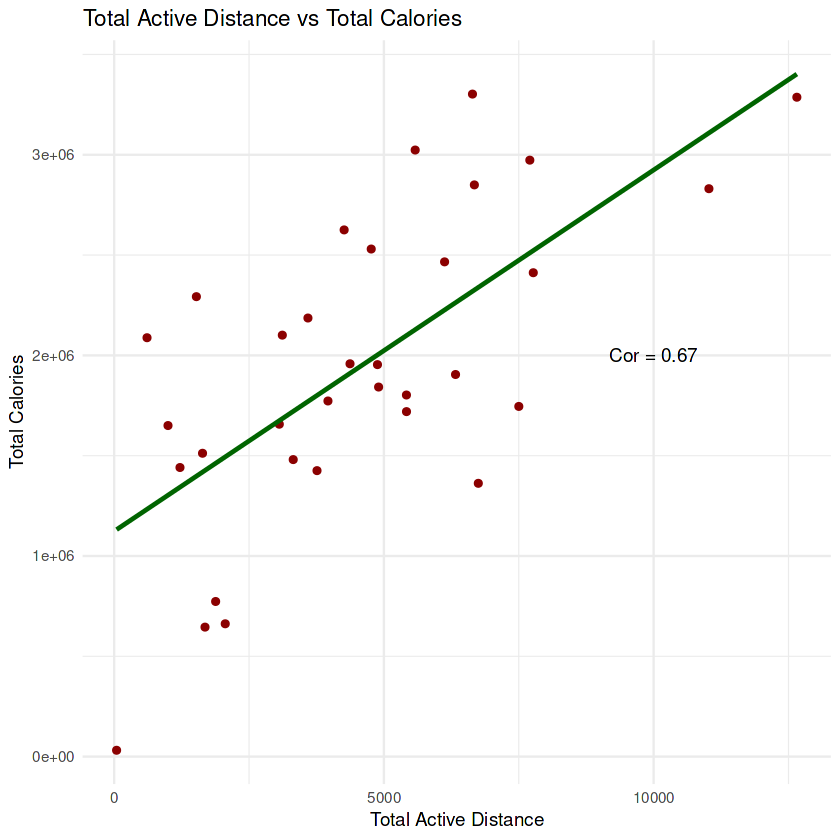

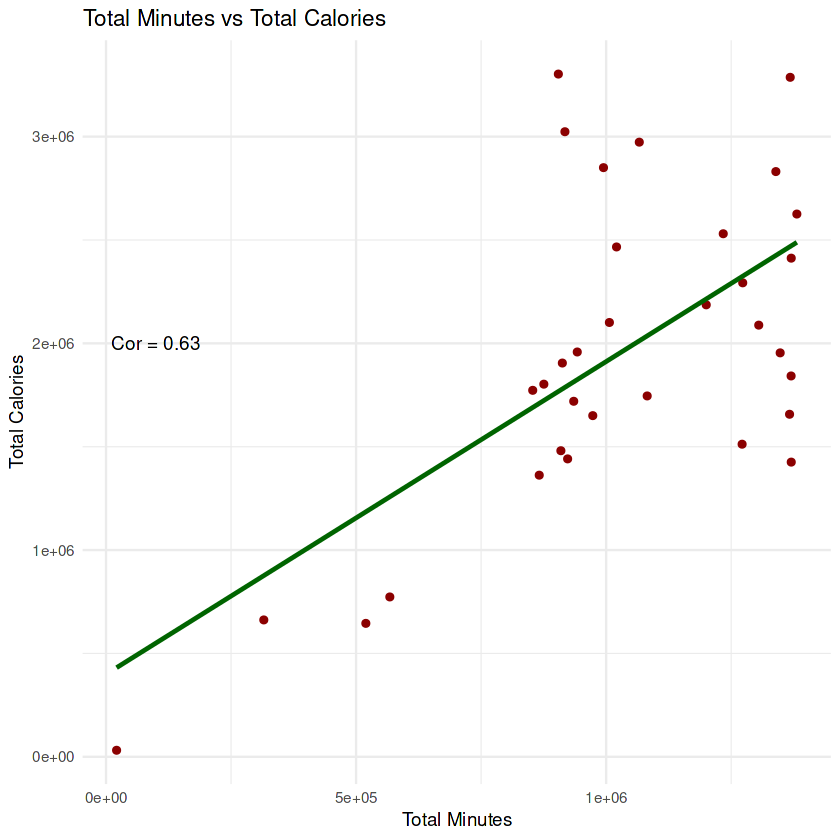

In [6]:
MinutesCaloriesCor <- cor(CaloriesData$TotalMinutes, CaloriesData$TotalCalories)
DistanceCaloriesCor <- cor(CaloriesData$TotalActiveDistance, CaloriesData$TotalCalories)
## Correlation Results
MinutesCaloriesCor
DistanceCaloriesCor
##Visualization
ggplot(CaloriesData, aes(x = TotalActiveDistance, y = TotalCalories)) +
  geom_point(color = "darkred") +
  geom_smooth(method = "lm", se = FALSE, color = "darkgreen") +
  labs(title = "Total Active Distance vs Total Calories",
       x = "Total Active Distance",
       y = "Total Calories") +
  annotate("text", x = 10000, y = 2e+06, label = "Cor = 0.67", color = "Black")+
  theme_minimal()

ggplot(CaloriesData, aes(x = TotalMinutes, y = TotalCalories)) +
  geom_point(color = "darkred") +
  geom_smooth(method = "lm", se = FALSE, color = "darkgreen") +
  labs(title = "Total Minutes vs Total Calories",
       x = "Total Minutes",
       y = "Total Calories") +
  annotate("text", x = 100000, y = 2e+06, label = "Cor = 0.63", color = "black")+
  theme_minimal()

Seems that distance traveled is a **slightly** better predictor of calories burned than total minutes of activity.
We test this with fisher's z transformation to see if the difference is **statistically significant**.

#### 3.1.3 Fisher's z TEST

In [7]:
# Fisher's Z Transformation
r1 <- DistanceCaloriesCor
r2 <- MinutesCaloriesCor
n <- nrow(CaloriesData)

z1 <- 0.5 * log((1 + r1) / (1 - r1))
z2 <- 0.5 * log((1 + r2) / (1 - r2))

se <- sqrt(1 / (n - 3))

z <- (z1 - z2) / se

z

[1] 0.3750199

### Are distance and minutes differently related to calories?
Distance (r = 0.67) showed a slightly higher **correlation** with calories than minutes (r = 0.63). Using Fisher's test for dependent correlations sharing the same criterion, the difference was **not statistically significant** (z = 0.38). Thus, distance may be a modestly better predictor in this sample, but we cannot **rule out sampling variability**.

### 3.2 Activity patterns
#### 3.2.1 Setup environment and upload data

In [42]:
##Upload
LastData <- read.csv("/kaggle/input/bella-beat/DailyActivity.csv")
SleepHabits <- read.csv("/kaggle/input/bella-beat/SleepDay.csv")
users_weight <- read.csv("/kaggle/input/bella-beat/WeightLogInfo.csv")


#### 3.2.2 Explore relationships and correlations

,Id,ActivityDate,TotalSteps,TotalDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
,<chr>,<date>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>
1,1503960366,2016-04-12,13162,8.50,1.88,0.55,6.06,0,25,13,328,728,1985
2,1503960366,2016-04-13,10735,6.97,1.57,0.69,4.71,0,21,19,217,776,1797
3,1503960366,2016-04-14,10460,6.74,2.44,0.40,3.91,0,30,11,181,1218,1776
4,1503960366,2016-04-15,9762,6.28,2.14,1.26,2.83,0,29,34,209,726,1745
5,1503960366,2016-04-16,12669,8.16,2.71,0.41,5.04,0,36,10,221,773,1863
6,1503960366,2016-04-17,9705,6.48,3.19,0.78,2.51,0,38,20,164,539,1728


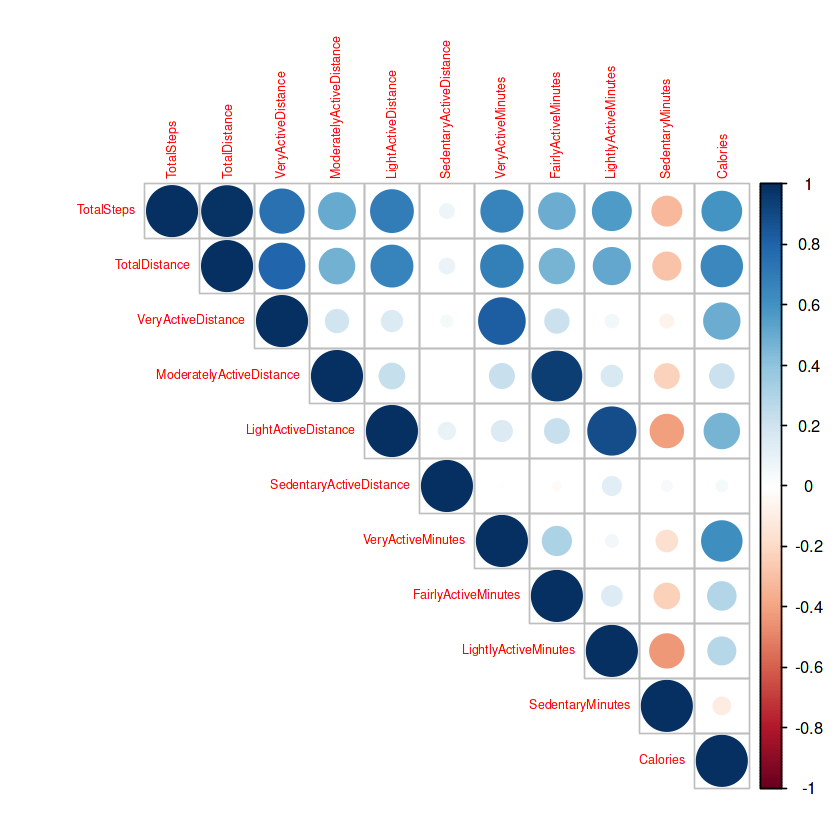

In [43]:
## Change The Date to proper format and remove unneeded columns
LastData2 <- LastData %>%
  mutate(Id = as.character(Id),
         ActivityDate = as.Date(ActivityDate, "%d/%m/%Y")) %>%
  select(-TrackerDistance,
         -LoggedActivitiesDistance)
head(LastData2)
## Find relationships between variables
AllCor <- LastData2 %>%
  select(-Id, -ActivityDate) %>%
  cor()

# Visualize the correlation matrix
corrplot(AllCor, method = "circle", type = "upper", tl.cex = 0.6)

#### 3.2.3 Visualiz with a heat map to a better view

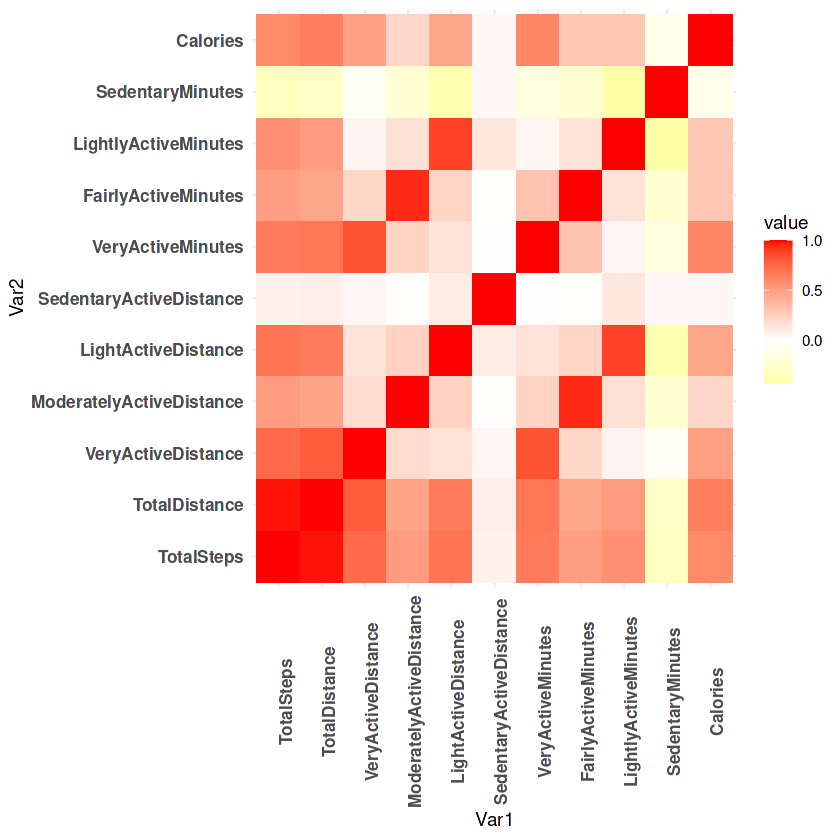

In [31]:
#Reshape Data for Heatmap
AllCor2 <- melt(AllCor)
#heatmap visualization
ggplot(AllCor2, aes(x = Var1, y = Var2, fill = value)) +
  geom_tile() +
  scale_fill_gradient2(low = "yellow", high = "red",
                       mid = "white", midpoint = 0) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 90, face = "bold", size = 10),
        axis.text.y = element_text(face= "bold", size = 10))

Too many variable **correlating** with each other,
so I will focus on the most relevant ones for BellaBeat's **interests**:

#### 3.2.4 Find Correlation between the variable we are interested in

[1] 0.5915681

[1] 0.7401146

[1] 0.6922082

[1] 0.5071054

[1] 0.6158383

[1] 0.7945816

[1] 0.6158383

[1] 0.2976235

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


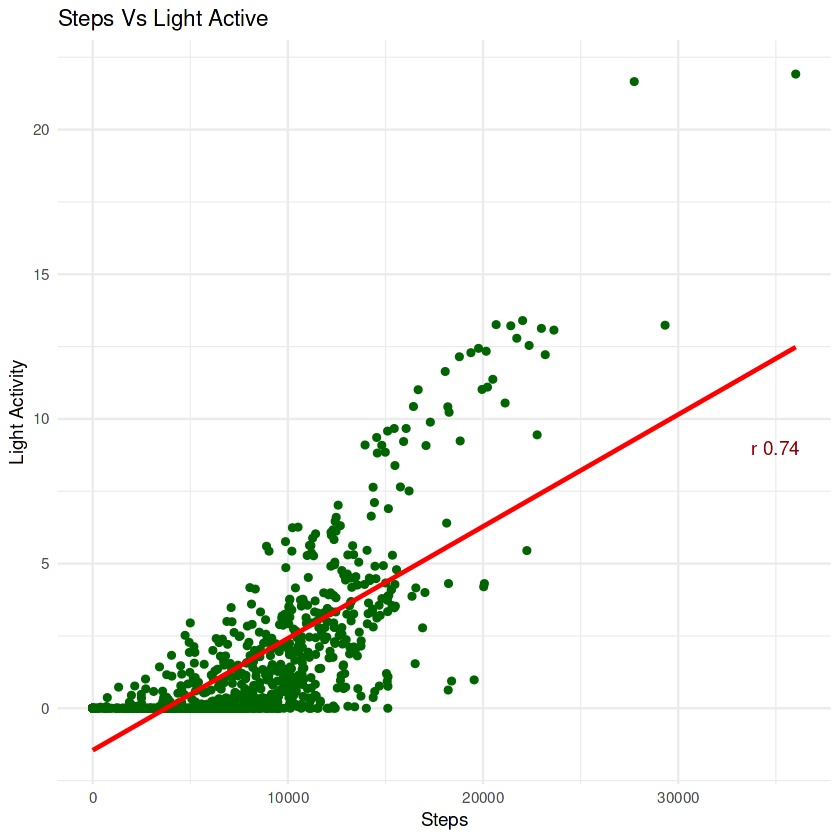

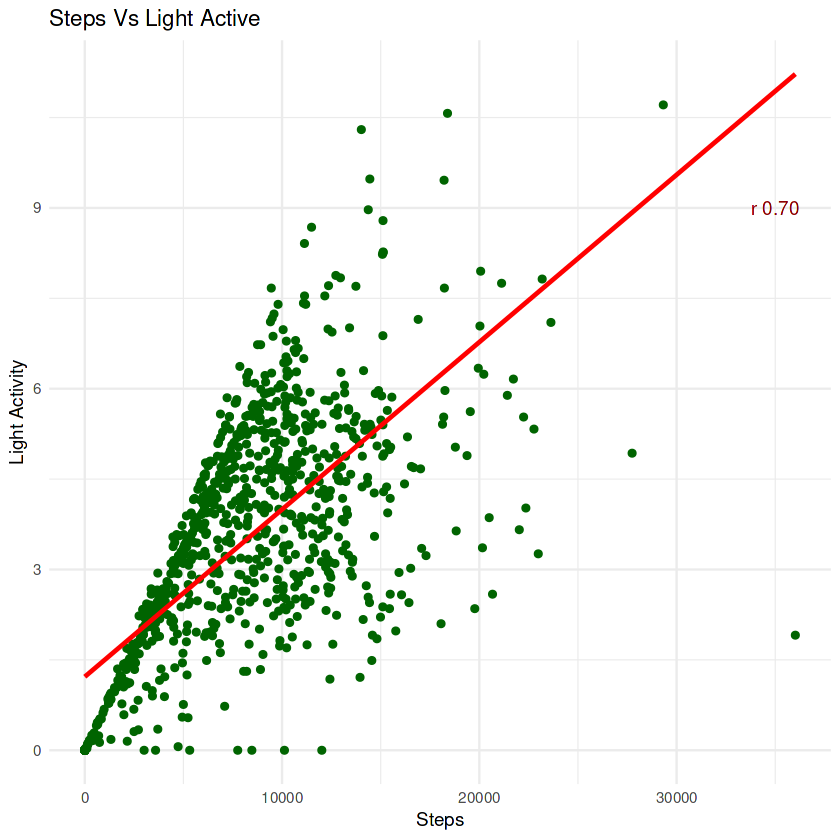

In [15]:
# Find Correlation between the variable we are interested in
StepsAndCalories <- cor(LastData$TotalSteps,LastData$Calories)
STepAndVeryActiveDistance <- cor(LastData$TotalSteps,LastData$VeryActiveDistance)
StepsAndLightlyActiveDistance <- cor(LastData$TotalSteps,LastData$LightActiveDistance)
StepsAndModeratlyDistance <- cor(LastData$TotalSteps,LastData$ModeratelyActiveDistance)
CaloriesAndVeryActiveMinutes <- cor(LastData$Calories,LastData$VeryActiveMinutes)
CaloriesAndFairlyActive <- cor(LastData$Calories,LastData$FairlyActiveMinutes)
TotalDistanceAndVeryActiveDistance <- cor(LastData$TotalDistance,LastData$VeryActiveDistance)

StepsAndCalories
STepAndVeryActiveDistance
StepsAndLightlyActiveDistance
StepsAndModeratlyDistance
CaloriesAndVeryActiveMinutes
TotalDistanceAndVeryActiveDistance
CaloriesAndVeryActiveMinutes
CaloriesAndFairlyActive

# Visualize the correlations
ggplot(LastData2,aes(x = TotalSteps, y = VeryActiveDistance)) +
  geom_point(colour = "darkgreen") +
  geom_smooth(method = lm, se = FALSE, colour = "red") +
  theme_minimal() +
  labs(title = "Steps Vs Light Active",
       x = "Steps",
       y = "Light Activity") +
  annotate("text", x = 35000, y = 9, label = "r 0.74", colour = "darkred")


ggplot(LastData2,aes(x = TotalSteps, y = LightActiveDistance)) +
  geom_point(colour = "darkgreen") +
  geom_smooth(method = lm, se = FALSE, colour = "red")+
  theme_minimal() +
  labs(title = "Steps Vs Light Active",
       x = "Steps",
       y = "Light Activity") +
  annotate("text", x = 35000, y = 9, label = "r 0.70", colour = "darkred")

### Conclusion & Recommendations

From the analysis, several key patterns emerged about user behavior and activity preferences:

1- Users prefer high-intensity activities
Most users spend more time in very active exercises such as running or gym workouts rather than moderate activities like cycling or brisk walking.

**Recommendation**: For users who mainly engage in light activities,
the app can encourage them to gradually try moderate-intensity activities.
This would provide a more achievable step toward reaching their health goals without requiring them to immediately commit to very intense exercise.

2- Very active minutes dominate total distance
The correlation analysis showed that total distance is most strongly explained by very active distance.
This means that users who engage in higher-intensity activity contribute the most to overall distance traveled,
which in turn burns the most calories.

**Recommendation**: Introduce goal-setting features that highlight how different activity levels contribute to calorie burn. For example,
a user could see how increasing moderate activity also helps them reach their calorie goals, even if they are not engaging in very high activity.

3- Opportunity to promote moderate activities
Since most users avoid moderate or fairly active activities, there’s an opportunity to brand these as accessible, beneficial,
and rewarding.

**Recommendation**: Create targeted challenges, educational content, or motivational nudges around moderate-intensity exercises.
This helps users feel represented in the app and attached to a fitness journey that feels realistic and sustainable.

### 3.3 Users and Most Activity Types
#### 3.3.1 Most Activity Types Users Prefer

Using Id as id variables



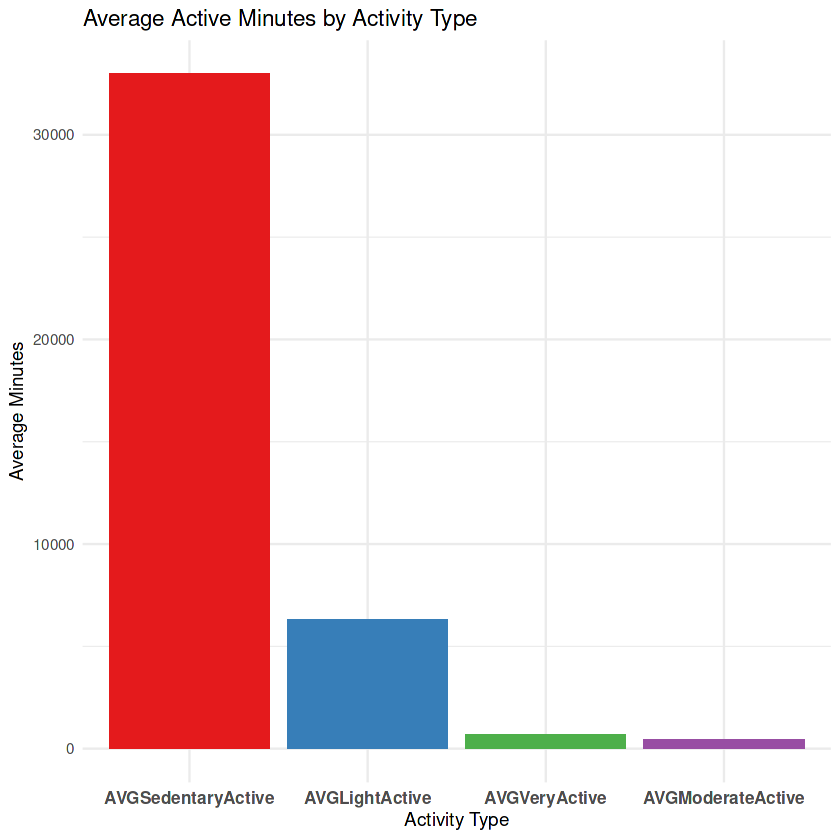

In [28]:
#reshape Data for Visualization
LastData3 <- LastData2 %>%
  group_by(Id) %>%
  summarise(AVGVeryActive = mean(VeryActiveMinutes),
            AVGModerateActive = mean(FairlyActiveMinutes),
            AVGLightActive = mean(LightlyActiveMinutes),
            AVGSedentaryActive = mean(SedentaryMinutes)) %>%
  melt() %>%
  mutate(variable = reorder(variable, -value))

# Visualization
ggplot(LastData3, aes(x = variable, y = value, fill = variable)) +
  geom_bar(stat = "identity") +
  scale_fill_brewer(palette = "Set1") +
  theme_minimal() +
  labs(title = "Average Active Minutes by Activity Type",
       x = "Activity Type",
       y = "Average Minutes") +
  theme(axis.text.x = element_text(face = "bold", size = 10)) +
  theme(legend.position = "none")

**The Very Active Activity** is the Activity that **users prefer** the most,
when it comes to An actual Activity

#### 3.3.2 Comparing Every Activity Used on Weekdays vs. Weekends

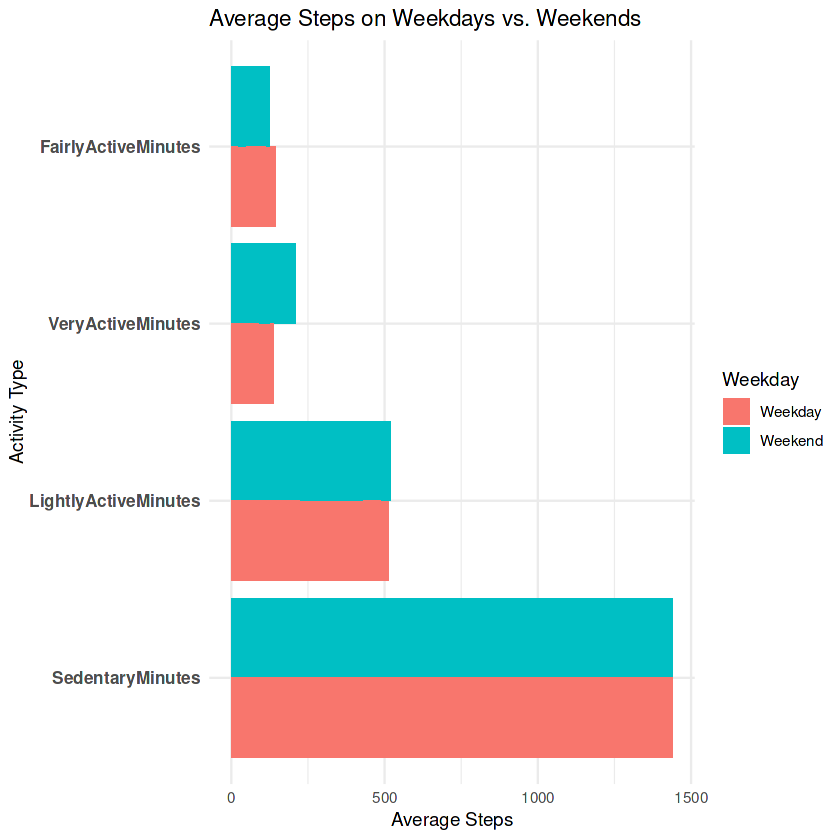

In [48]:
  #Reshape Data for Visualization
  ActivityDay <- LastData2  %>%
    mutate(Weekday = ifelse(weekdays(ActivityDate) %in%
                              c("Saturday", "Sunday"), "Weekend", "Weekday")) %>%
    select(Weekday, VeryActiveMinutes,
          FairlyActiveMinutes, LightlyActiveMinutes,
          SedentaryMinutes) %>%
    pivot_longer(cols = c(VeryActiveMinutes,
                          FairlyActiveMinutes, LightlyActiveMinutes,
                          SedentaryMinutes),
                names_to = "ActivityType",
                values_to = "Value") %>%
    mutate(ActivityType = reorder(ActivityType, -Value))


  # Visualization
ggplot(ActivityDay, aes(x = ActivityType, y = Value, fill = Weekday)) +
  geom_col(position = "dodge") +
  coord_flip() +
  theme_minimal() +
  labs(
    title = "Average Steps on Weekdays vs. Weekends",
    x = "Activity Type",
    y = "Average Steps") +
  theme(axis.text.y = element_text(face = "bold", size = 10))

### Weekday vs. Weekend Activity Patterns

- Users tend to engage in **fairly active activities** (e.g., brisk walking) **during weekdays**, likely due to work and daily routines.

- On **weekends**, users shift toward **very active activities** (e.g., running, gym, sports), when they have more free time.

- Despite the increase in very active minutes and distance on weekends, the total calories burned and total steps show only a modest difference compared to weekdays.

#### 3.3.3 Comparing Calories Burned And Steps on Weekdays vs. Weekends

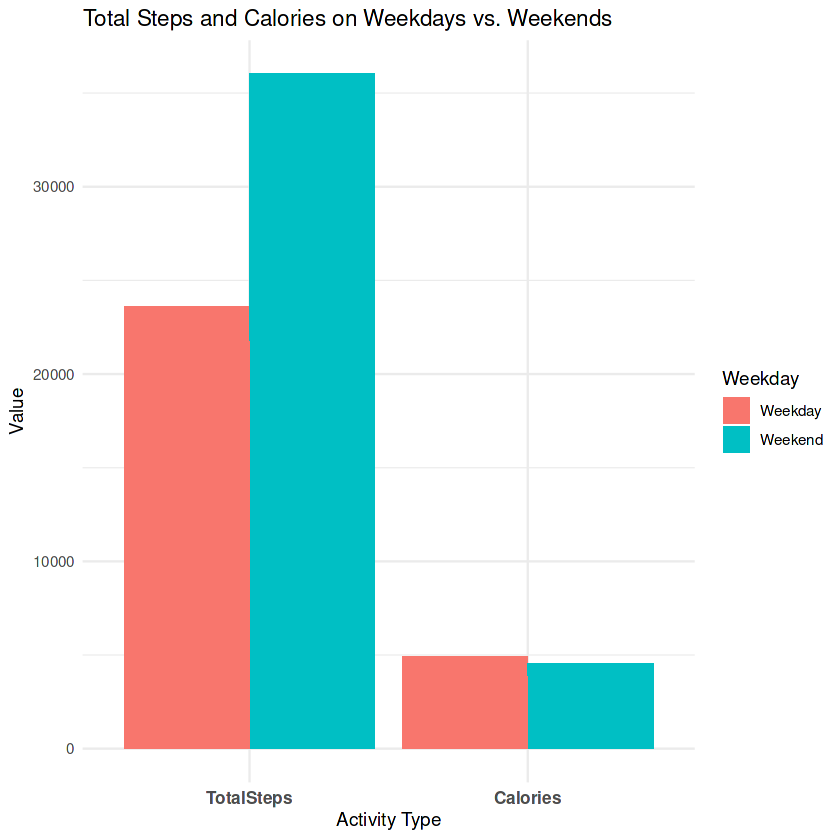

In [51]:
# Reshape Data for Visualization
StepDay <- LastData2  %>%
  mutate(Weekday = ifelse(weekdays(ActivityDate) %in%
                            c("Saturday", "Sunday"), "Weekend", "Weekday")) %>%
  select(Weekday, TotalSteps, Calories) %>%
  pivot_longer(cols = c(TotalSteps, Calories),
               names_to = "ActivityType",
               values_to = "Value") %>%
  mutate(ActivityType = reorder(ActivityType, -Value))

# Visualization
ggplot(StepDay, aes(x = ActivityType, y = Value, fill = Weekday)) +
  geom_col(position = "dodge") +
  theme_minimal() +
  labs(title = "Total Steps and Calories on Weekdays vs. Weekends",
       x = "Activity Type",
       y = "Value")+
  theme(axis.text.x = element_text(face = "bold", size = 10))

### Steps and Calories: Weekday vs. Weekend

- Total steps are **higher** on weekends compared to weekdays, reflecting the increase in **very active activities** during free time.

- **However**, the difference in calories burned *is not as large as* the difference in steps.

- This supports the earlier finding that very active activities contribute more to calorie burn efficiency than fairly active ones, even if both add to total steps.

### 3.4 Exploring Sleep Patterns
#### 3.4.1 Find Correlation between Sleep and Activity "Correlation Matrix"

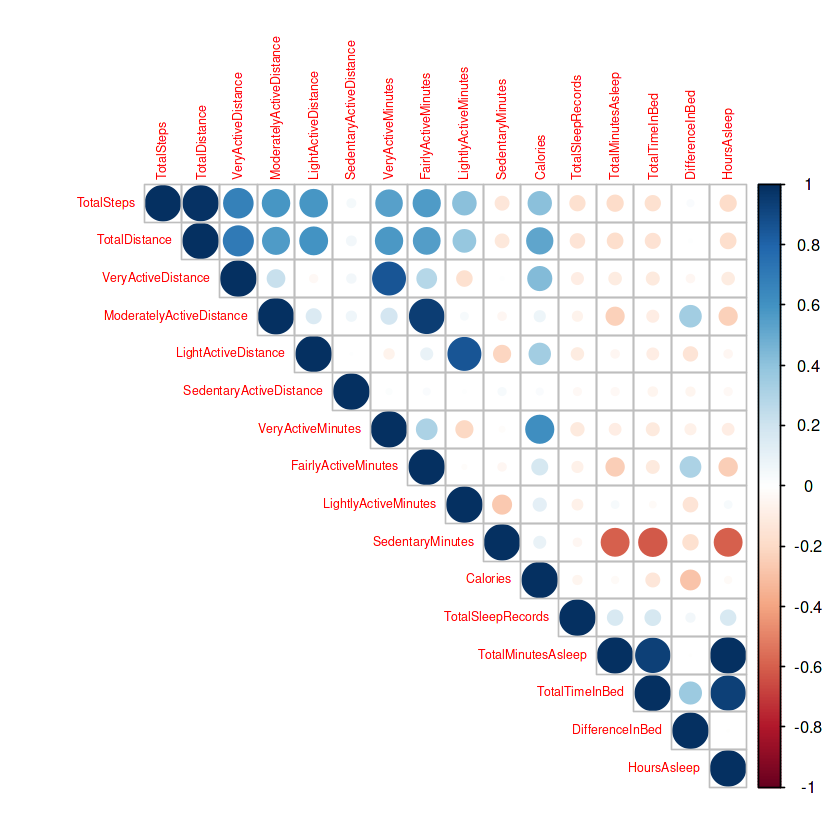

In [52]:
# Clean and Enahance Sleep Data and Add New Columns
Sleep1 <- SleepHabits %>%
  mutate(Id = as.character(Id),
         SleepDay = as.Date(SleepDay, "%Y-%m-%d")) %>%
  mutate(DifferenceInBed = TotalTimeInBed - TotalMinutesAsleep) %>% 
  mutate(HoursAsleep = (TotalMinutesAsleep/60))

# Merge Sleep Data with Activity Data
SleepVsActivity <- merge(LastData2, Sleep1,by.x = c("Id","ActivityDate"),
                         by.y = c("Id", "SleepDay"))

SleepVsActivityCorr <- SleepVsActivity %>%
  select(where(is.numeric)) %>%
  cor(use = "pairwise.complete.obs")

# Visualize the correlation matrix
corrplot(SleepVsActivityCorr,method = "circle", type = "upper", tl.cex = 0.6)

#### 3.4.2 Find Correlation between Sleep and Activity "Heat Map"

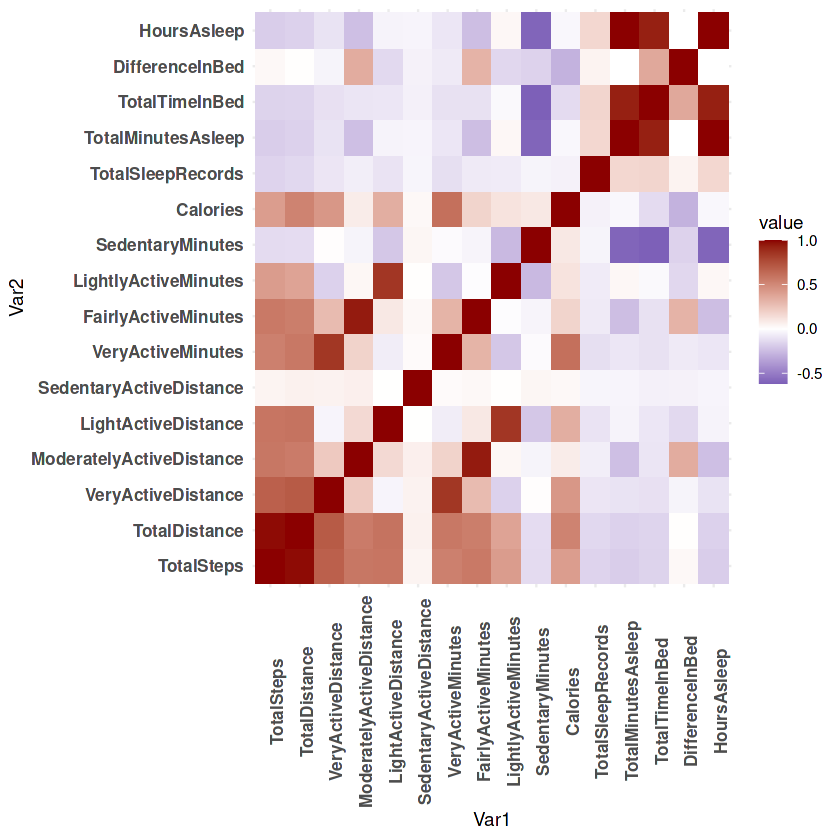

In [54]:
#Reshape Data for Heatmap
SleepVsActivityMelt <- melt(SleepVsActivityCorr)

#heatmap visualization
ggplot(SleepVsActivityMelt, aes(x = Var1, y = Var2, fill = value)) +
  geom_tile() +
  scale_fill_gradient2(low = "darkblue", high = "darkred",
                       mid = "white", midpoint = 0) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 90))+
  theme(axis.text.x = element_text(angle = 90, face = "bold", size = 10),
        axis.text.y = element_text(face= "bold", size = 10))

#### 3.4.3 Find Correlation between Variables We Are Interested In

[1] 0.9304575

[1] -0.599394

[1] -0.1654363

[1] -0.07718889

[1] -0.1868665

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'
`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


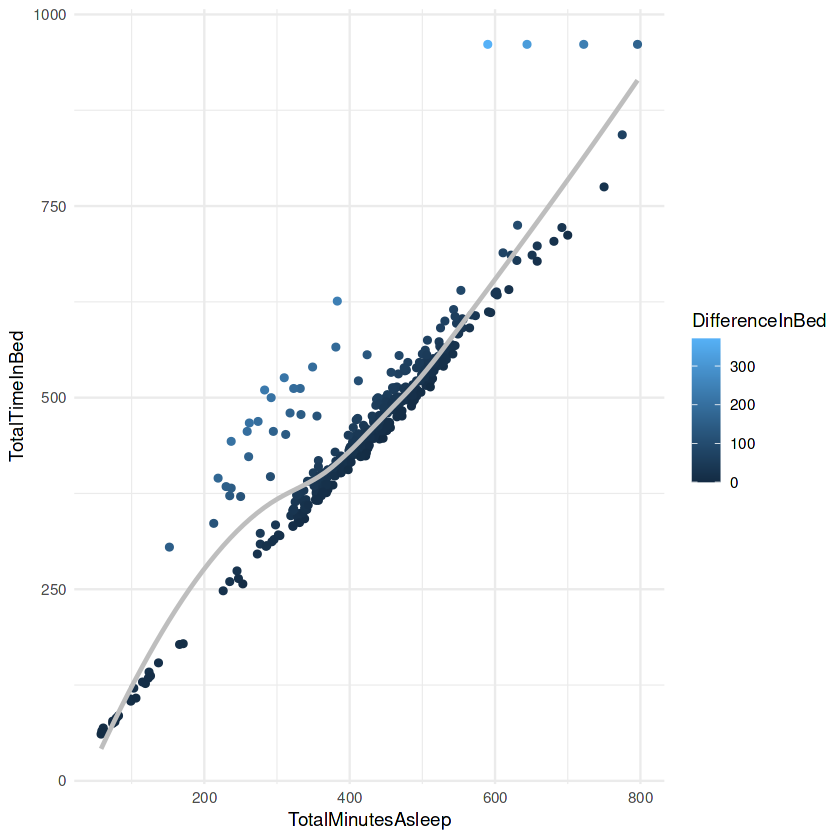

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


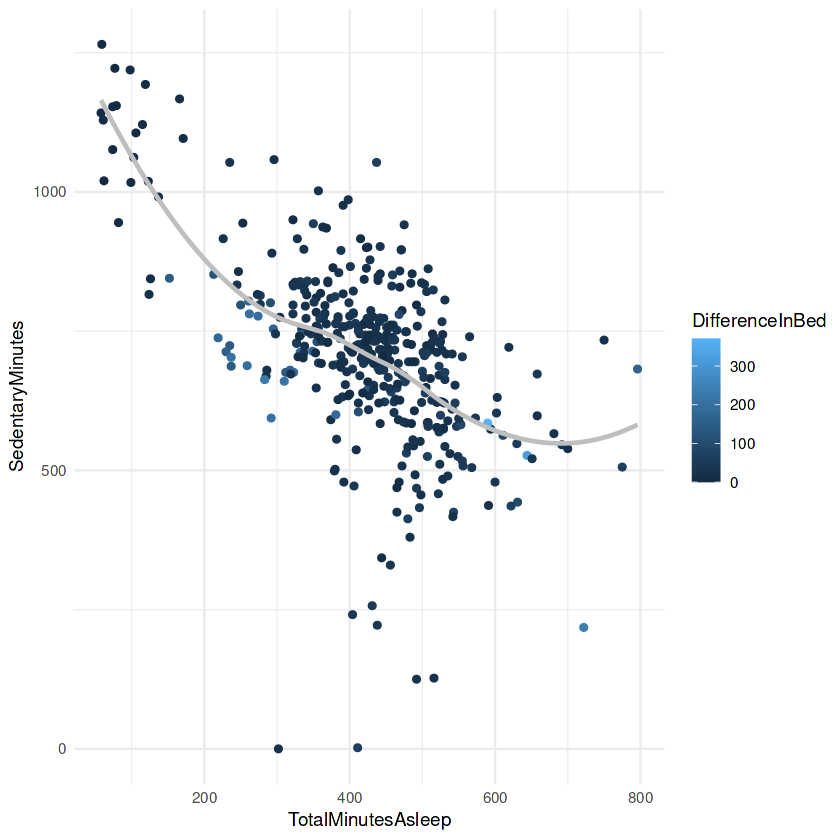

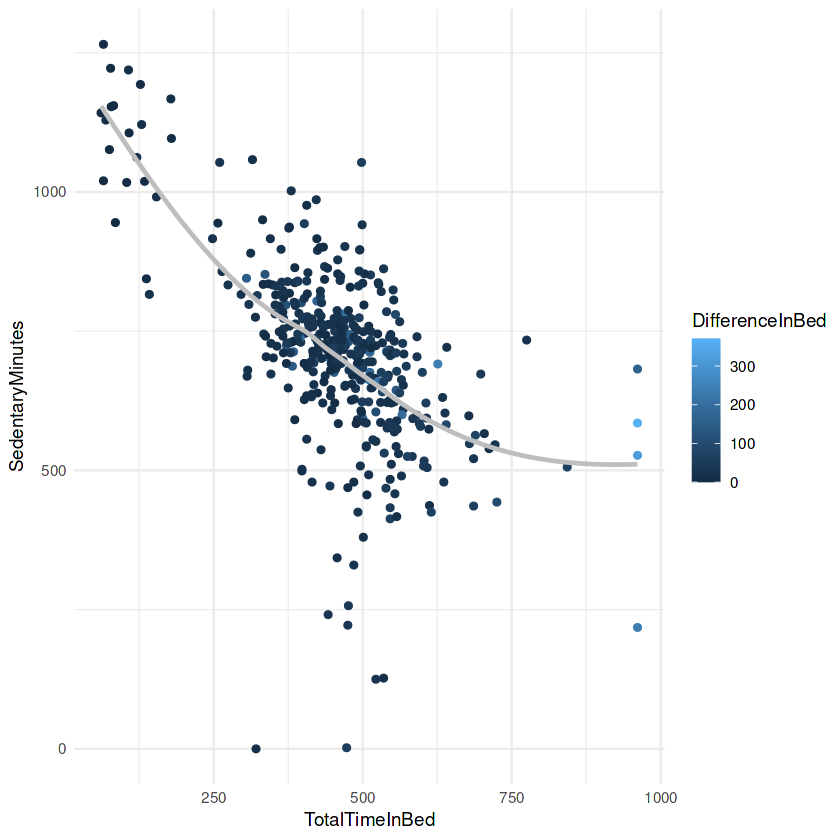

In [55]:
#correlations
DiffernceVsSedentryActivity <- cor(SleepVsActivity$DifferenceInBed,SleepVsActivity$SedentaryMinutes)
DiffernceVsVeryActive <- cor(SleepVsActivity$DifferenceInBed,SleepVsActivity$VeryActiveMinutes)
MinutesAsleepVsSedentryActivity <- cor(SleepVsActivity$TotalMinutesAsleep,SleepVsActivity$SedentaryMinutes)
MinutesInBedVsMinutesAsleep <- cor(SleepVsActivity$TotalMinutesAsleep,SleepVsActivity$TotalTimeInBed)
TotalStepsVsMinutesAsleep <- cor(SleepVsActivity$TotalMinutesAsleep,SleepVsActivity$TotalSteps)
TotalStepsVstotalDistance <- cor(SleepVsActivity$TotalSteps,SleepVsActivity$ModeratelyActiveDistance)

MinutesInBedVsMinutesAsleep
MinutesAsleepVsSedentryActivity
DiffernceVsSedentryActivity
DiffernceVsVeryActive
TotalStepsVsMinutesAsleep

#visualization

ggplot(SleepVsActivity,aes(x = TotalMinutesAsleep, y = TotalTimeInBed,colour = DifferenceInBed)) +
  geom_point()+
  geom_smooth(se = F,colour = "gray")+
  theme_minimal()

ggplot(SleepVsActivity,aes(x = TotalMinutesAsleep, y = SedentaryMinutes,colour = DifferenceInBed)) +
  geom_point() +
  geom_smooth(se = F,colour = "gray") +
  theme_minimal()

ggplot(SleepVsActivity,aes(x = TotalTimeInBed, y = SedentaryMinutes,colour = DifferenceInBed))+
  geom_point() +
  geom_smooth(se = F,colour = "gray") +
  theme_minimal()

### Sleep Patterns and Their Impact

1- Some users spend a **long time** in bed without actually sleeping, indicating possible **sleep quality issues**.

2- Users who are **less active** during the day tend to sleep longer than usual, suggesting that insufficient activity may affect **sleep efficiency**.

3- By analyzing both distance covered and total minutes asleep, we can see a **relationship** between **daily activity** and **sleep quality**.

### Recommendation

1- Introduce a sleep tracking feature that sets **personalized sleep goals** (e.g., 7–8 hours of quality sleep).

2- Provide educational insights on how **better sleep** improves **health and daily performance**.

3- Connect sleep goals with activity tracking, encouraging users to **stay active** during the day to improve their **sleep quality**.

4- This integration can help users achieve **better sleep**, **better health**, and more **efficient calorie burn**.

#### 3.4.4 Users Sleep Habits With Steps he Takes
After we found the correlation between **Steps** and **Distance**,
we can find the correlation between **Distance** and **Sleep Habits**, 
And Then Find the **Steps** based on the **Distance**,
Because Distance is small, easy to understand, and easy to visualizewith the Sleep Habits

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


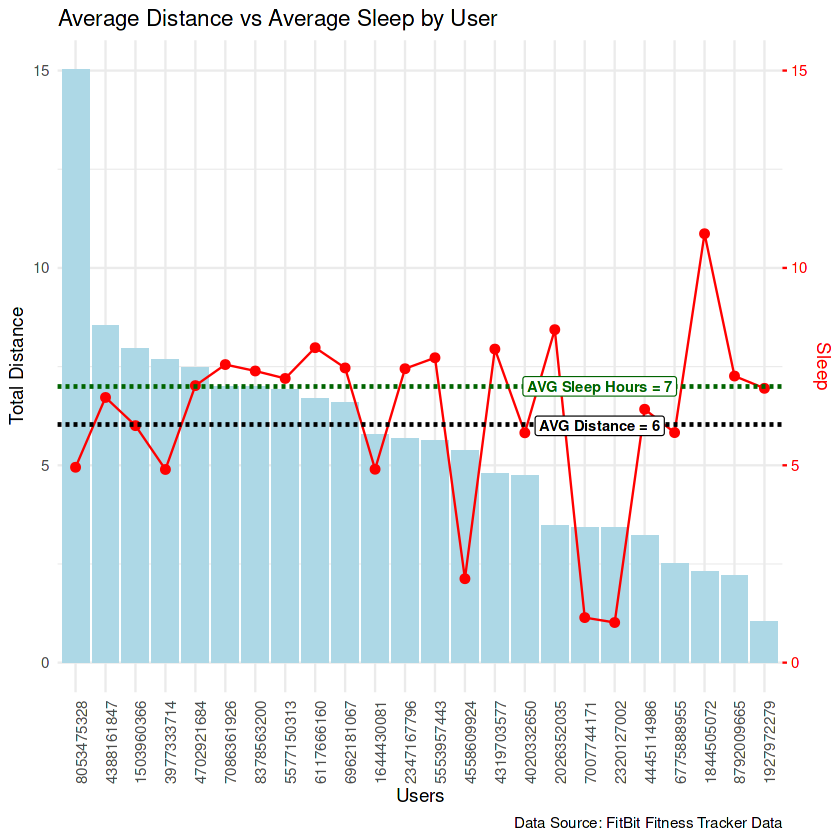

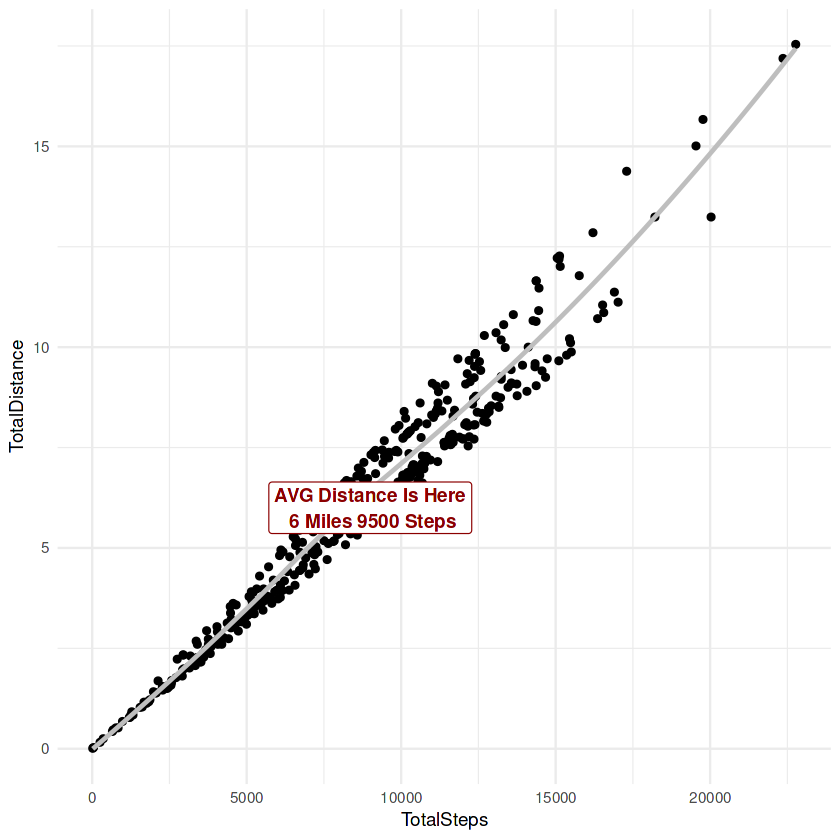

In [56]:
# Reshape Data and Aggregate it
AggergatingDistanceAndSleep <- SleepVsActivity %>%
  select(Id, TotalDistance, HoursAsleep) %>%
  group_by(Id) %>%
  summarise(
    TotalDistance = mean(TotalDistance, na.rm = TRUE),
    HoursAsleep = mean(HoursAsleep, na.rm = TRUE)
  ) %>%
  drop_na() %>%
  mutate(Id = reorder(Id, -TotalDistance))

# Visualization For Sleep And Distance
ggplot(AggergatingDistanceAndSleep, aes(x = factor(Id))) +
  geom_col(aes(y = TotalDistance), fill = "lightblue") +
  geom_line(aes(y = HoursAsleep), color = "red", group = 1) +
  geom_point(aes(y = HoursAsleep), color = "red", size = 2) +
  geom_hline(yintercept = mean(SleepVsActivity$TotalDistance, na.rm = TRUE),
             linetype = "dashed", color = "black", size = 1) + 
  geom_hline(yintercept = mean(SleepVsActivity$HoursAsleep, na.rm = TRUE),
             linetype = "dashed", color = "darkgreen", size = 1) +
  scale_y_continuous(
    name = "Total Distance",
    sec.axis = sec_axis(~ ., name = "Sleep")
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1),
    axis.title.y.right = element_text(color = "red"),
    axis.ticks.y.right = element_line(color = "red"),
    axis.text.y.right = element_text(color = "red")) +
  labs(
    title = "Average Distance vs Average Sleep by User",
    x = "Users",
    caption = "Data Source: FitBit Fitness Tracker Data"
  ) +
  annotate("label", y = 6, x = 18.5, 
              label = "AVG Distance = 6",
           fontface = "bold",
          fill = "white",
          size = 3) +
  annotate("label", y = 7, x = 18.5, 
           label = "AVG Sleep Hours = 7",
           fontface = "bold",
           fill = "white",
           size = 3,
           colour = "darkgreen")

##Find Stesp Based on Distance
ggplot(SleepVsActivity,aes(x = TotalSteps, y = TotalDistance))+
  geom_point() +
  geom_smooth(se = F,colour = "gray") +
  theme_minimal()+
  annotate("label", x = 9000, y = 6, label = "AVG Distance Is Here\n 6 Miles 9500 Steps",
           colour = "darkred",fill = "white", fontface = "bold")

### Sleep and Activity Connection

Users who engage in **fewer daily activities** and **over less distance** tend to have **poorer sleep quality**.

The analysis shows that users with **distances below the average** (around 6 km ≈ 9,500 steps) 
are more likely to experience **trouble with sleep** compared to more active users.

### Recommendation

Introduce a **daily step goal feature** (e.g., encouraging users to reach 10,000 steps per day) to promote **better sleep quality**.

This can be paired with motivational nudges and progress tracking, helping users understand that even moderate increases in activity 
not only improve fitness but also support healthier sleep patterns.

### 3.5 Explore Weight Log Info
#### 3.5.1 View it

In [59]:
# View Data
head(users_weight)
str(users_weight)

# Filter Unique Users
filter_users_weight <- users_weight %>%
  distinct(Id, .keep_all = TRUE)

View(filter_users_weight)

,Id,Date,WeightKg,WeightPounds,Fat,BMI,IsManualReport,LogId
,<dbl>,<chr>,<dbl>,<dbl>,<int>,<dbl>,<lgl>,<dbl>
1,1503960366,2016-05-02,52.6,115.9631,22,22.65,TRUE,1.46e+12
2,1503960366,2016-05-03,52.6,115.9631,NA,22.65,TRUE,1.46e+12
3,1927972279,2016-04-13,133.5,294.3171,NA,47.54,FALSE,1.46e+12
4,2873212765,2016-04-21,56.7,125.0021,NA,21.45,TRUE,1.46e+12
5,2873212765,2016-05-12,57.3,126.3249,NA,21.69,TRUE,1.46e+12
6,4319703577,2016-04-17,72.4,159.6147,25,27.45,TRUE,1.46e+12


'data.frame':	67 obs. of  8 variables:
 $ Id            : num  1.50e+09 1.50e+09 1.93e+09 2.87e+09 2.87e+09 ...
 $ Date          : chr  "2016-05-02" "2016-05-03" "2016-04-13" "2016-04-21" ...
 $ WeightKg      : num  52.6 52.6 133.5 56.7 57.3 ...
 $ WeightPounds  : num  116 116 294 125 126 ...
 $ Fat           : int  22 NA NA NA NA 25 NA NA NA NA ...
 $ BMI           : num  22.6 22.6 47.5 21.5 21.7 ...
 $ IsManualReport: logi  TRUE TRUE FALSE TRUE TRUE TRUE ...
 $ LogId         : num  1.46e+12 1.46e+12 1.46e+12 1.46e+12 1.46e+12 ...


Id,Date,WeightKg,WeightPounds,Fat,BMI,IsManualReport,LogId
<dbl>,<chr>,<dbl>,<dbl>,<int>,<dbl>,<lgl>,<dbl>
1503960366,2016-05-02,52.6,115.9631,22,22.65,TRUE,1.46e+12
1927972279,2016-04-13,133.5,294.3171,NA,47.54,FALSE,1.46e+12
2873212765,2016-04-21,56.7,125.0021,NA,21.45,TRUE,1.46e+12
4319703577,2016-04-17,72.4,159.6147,25,27.45,TRUE,1.46e+12
4558609924,2016-04-18,69.7,153.6622,NA,27.25,TRUE,1.46e+12
5577150313,2016-04-17,90.7,199.9593,NA,28.00,FALSE,1.46e+12
6962181067,2016-04-12,62.5,137.7889,NA,24.39,TRUE,1.46e+12
8877689391,2016-04-12,85.8,189.1566,NA,25.68,FALSE,1.46e+12


### Weight Data Availability

Weight records are available for only 8 out of 33 users, which represents a small portion of the dataset.

This limited sample raises the question: 
Are these users representative of the audience we are targeting, or do they reflect a specific subgroup with different behaviors and goals?

#### 3.5.2 Find the Users We Are Interested In

In [62]:
SleepVsActivityWeight <- merge(SleepVsActivity, filter_users_weight, by = "Id") %>%
  distinct(Id)
View(SleepVsActivityWeight)

Id
<chr>
1503960366
1927972279
4319703577
4558609924
5577150313
6962181067


### Weight Data Integrity

Out of the 8 users who provided weight records, only 6 belong to the target user group.
This small and inconsistent sample size limits the reliability of weight-related insights.
Therefore, we cannot rely on this data with integrity for broader analysis or decision-making.

### 3.6 Causation Attempts
#### 3.6.1 Does the poor sleep affect steps and calories next day

[1] -0.1386145

[1] -0.02017746

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 24 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 24 rows containing missing values or values outside the scale range
(`geom_point()`).”


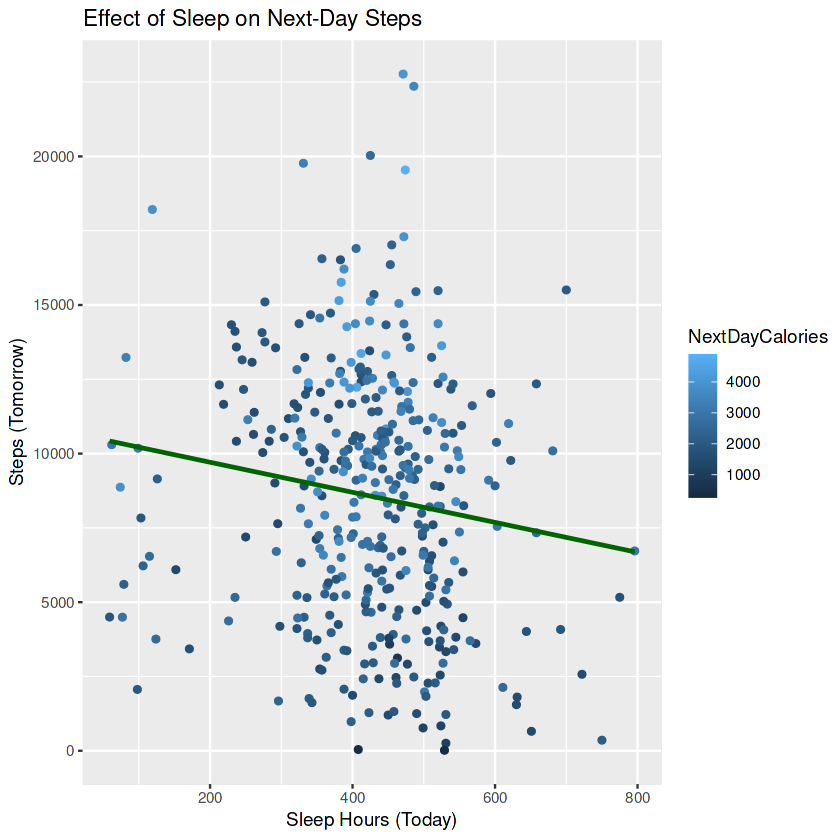

In [63]:
#Reshape Data
SleepVsActivityLag <- SleepVsActivity %>%
  arrange(Id, ActivityDate) %>%
  group_by(Id) %>%
  mutate(
    NextDaySteps = lead(TotalSteps),
    NextDayCalories = lead(Calories),
    PrevNightSleep = lag(TotalMinutesAsleep)
  )

#correlation test
Steps <- cor(SleepVsActivityLag$TotalMinutesAsleep,SleepVsActivityLag$NextDaySteps, use = "complete.obs")
Calories <- cor(SleepVsActivityLag$TotalMinutesAsleep,SleepVsActivityLag$NextDayCalories, use = "complete.obs")

Steps
Calories

##Visualization
ggplot(SleepVsActivityLag, aes(x = TotalMinutesAsleep, y = NextDaySteps, colour = NextDayCalories)) +
  geom_point() +
  geom_smooth(method = "lm", se = FALSE, color = "darkgreen") +
  labs(title = "Effect of Sleep on Next-Day Steps",
       x = "Sleep Hours (Today)",
       y = "Steps (Tomorrow)")

#### 3.6.2 Try with the 10k Steps Goal

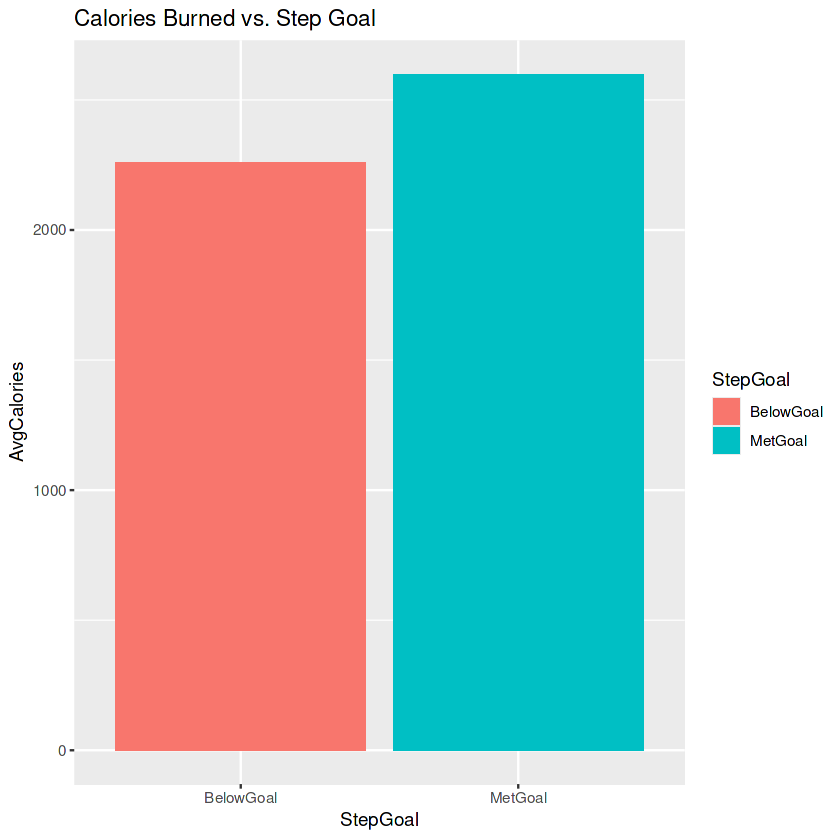

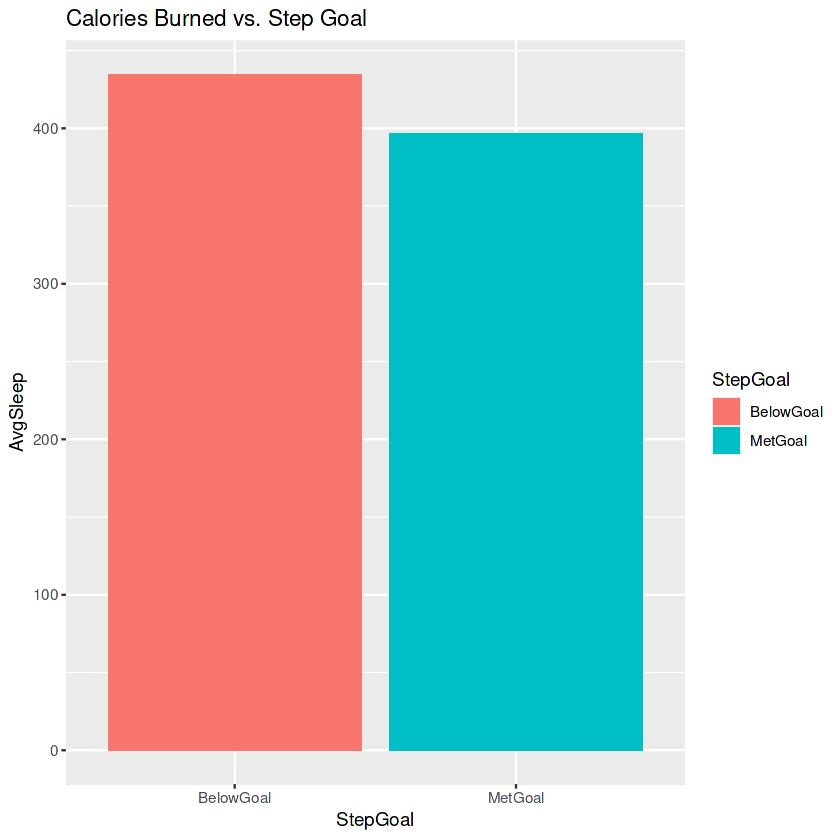

In [64]:
StepGoalAnalysis <- SleepVsActivity %>%
  mutate(StepGoal = ifelse(TotalSteps >= 10000, "MetGoal", "BelowGoal")) %>%
  group_by(StepGoal) %>%
  summarise(
    AvgCalories = mean(Calories, na.rm = TRUE),
    AvgSleep = mean(TotalMinutesAsleep, na.rm = TRUE),
    AvgActiveMinutes = mean(VeryActiveMinutes, na.rm = TRUE)
  )

# Visualization
ggplot(StepGoalAnalysis, aes(x = StepGoal, y = AvgCalories, fill = StepGoal)) +
  geom_col() +
  labs(title = "Calories Burned vs. Step Goal")

#Visualization
ggplot(StepGoalAnalysis, aes(x = StepGoal, y = AvgSleep, fill = StepGoal)) +
  geom_col() +
  labs(title = "Calories Burned vs. Step Goal")

### Steps vs. Sleep Quality

At first glance, reaching 10,000 steps daily should correlate with higher calorie burn — and indeed, it does.
However, when comparing sleep, the data shows an interesting pattern:
Users below the 10k step goal actually recorded a higher average sleep duration than those who consistently met the goal.

This suggests that while increased activity improves calorie expenditure, it does not necessarily translate into better or longer sleep.

-------------------------------------------------------------------------------------------------------------------------------------------------

# Conclusion & Strategic Recommendations  

## Data Integrity & Scale  
- The dataset includes data from **33 users**, but not all features were consistently recorded.  
- For example, **weight data** exists for only 8 users, and just **6 of them fall into the target user segment**.  
- This limited scale means we should be **cautious in drawing broad conclusions**, but the patterns observed still provide **valuable signals** for user behavior and app improvement.  

---

## Key Findings & Marketing Insights  

### 1. Activity Preferences  
- Users prefer **very active exercises** (running, gym workouts) over **moderate activities** (cycling, brisk walking).  
- **Total distance** is strongly correlated with **very active distance**, showing that intense activity dominates calorie burn.  

**Recommendation:**  
- Position the app as supportive of both **high-intensity users** and those who are just starting out.  
- Create **campaigns that highlight the benefits of moderate activity** to attract a wider audience that may feel excluded by high-intensity branding.  

---

### 2. Weekday vs. Weekend Activity  
- On **weekends**, users walk **more steps** compared to weekdays.  
- However, **calorie burn differs significantly**, confirming that **very active minutes (common on weekends)** drive more calorie expenditure than fairly active minutes.  

**Recommendation:**  
- Launch **weekend challenges** (e.g., “Weekend Warrior”) to gamify higher activity.  
- Highlight the **efficiency of intense activities** in marketing campaigns, showing how users can maximize calorie burn even in short time windows.  

---

### 3. Sleep & Activity Connection  
- Some users spend **long hours in bed without actually sleeping**, suggesting **poor sleep efficiency**.  
- Users with **less daily activity** tend to sleep longer, but not necessarily better.  
- Interestingly, users who met the **10k step goal burned more calories** but actually slept **less on average** than those below the goal.  

**Recommendation:**  
- Promote a **holistic health approach** by linking activity to **better-quality sleep**, not just duration.  
- Introduce a **sleep tracking feature** with educational content on how activity supports sleep and recovery.  
- Encourage users with goals like: *“10k steps + 7–8 hours of quality sleep = best health balance.”*  

---

### 4. Weight Data Limitations  
- Weight data is available for only **a small subset of users (6–8 out of 33)**, making it unreliable for broad insights.  

**Recommendation:**  
- Use this as an opportunity to **encourage more weight and body data tracking** within the app.  
- Position these features as **personalized progress tools**, reassuring users of **privacy** while promoting accountability.  

---

##  Final Strategic Recommendations  
1. **Broaden the appeal:** Market the app not just to fitness enthusiasts but also to everyday users by emphasizing **moderate, approachable activities**.  
2. **Highlight efficiency:** Campaigns should show how short bursts of **very active exercise** have an outsized impact on calorie burn.  
3. **Promote holistic health:** Combine **activity + sleep goals** in marketing messages to stand out from competitors focusing only on steps/calories.  
4. **Engage through challenges:** Introduce **weekday vs. weekend challenges**, **moderate activity streaks**, and **sleep-improvement journeys**.  
5. **Address data gaps:** Encourage users to track more metrics (e.g., weight, sleep, activity type) to unlock **personalized insights** and keep them engaged.  

**Highlighting** efficiency, and connecting activity with sleep, **Bellabeat** can position itself not just as a *fitness tracker*, 
but as a **holistic lifestyle companion** — driving stronger engagement, higher user retention, and stronger market differentiation.
---

In short: while the dataset scale is limited, the analysis uncovers **clear behavioral patterns** that can guide a **marketing strategy focused on inclusivity, personalization, and holistic wellness**.